In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick

import seaborn as sns
from matplotlib.ticker import FuncFormatter

import squarify

In [ ]:
#pip install --upgrade openpyxl


Weekly Visits
    Regular Visits v. Unique Visits with period shading* - yes
    Pages/Visit compared to avg time on site with total pageviews bubble chart* + metric * - yes
    % of new visits v bounce rate * - yes

Financials
    weekly profict v pounds sold* - yes
    scatter plot of inqiuresvtimeonsite*
    lbs sold per each period* - yes
    
Demographics
    proportion of visits by geographic region - yes

In [2]:
xls = pd.ExcelFile('qa.xlsx')
print(xls.sheet_names)
#financialdf = pd.read_excel(xls, sheet_name='Financials')
poundsdf = pd.read_excel(xls, sheet_name='Lbs. Sold')
dailydf = pd.read_excel(xls, sheet_name='Daily Visits')
demodf = pd.read_excel(xls, sheet_name='Demographics')



['Columbia CaseWorks', 'Weekly Visits', 'Financials', 'Lbs. Sold', 'Daily Visits', 'Demographics']


WEEKLY

In [3]:
#Weekly visits

df = pd.read_excel("qa.xlsx", sheet_name="Weekly Visits", header=4)
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]
print(df.head())


  Week (2008-2009)  Visits  Unique Visits  Pageviews  Pages/Visit  \
0  May 25 - May 31    1632           1509       3328         2.04   
1    Jun 1 - Jun 7    1580           1450       3097         1.96   
2   Jun 8 - Jun 14    1441           1306       3202         2.22   
3  Jun 15 - Jun 21    1452           1301       3170         2.18   
4  Jun 22 - Jun 28    1339           1255       2366         1.77   

   Avg. Time on Site (secs.)  Bounce Rate  % New Visits  
0                         71       0.7267        0.8854  
1                         56       0.7551        0.8734  
2                         79       0.7398        0.8432  
3                         81       0.7362        0.8437  
4                         50       0.7640        0.8925  


In [37]:
print(list(weeklydf.columns)) 

['Quality Alloys', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7']


In [4]:
# clean up the week column
df['Week (2008-2009)'] = df['Week (2008-2009)'].str.split(' - ').str[0]
df.rename(columns={'Week (2008-2009)': 'Week'}, inplace=True)
print(df.head())

     Week  Visits  Unique Visits  Pageviews  Pages/Visit  \
0  May 25    1632           1509       3328         2.04   
1   Jun 1    1580           1450       3097         1.96   
2   Jun 8    1441           1306       3202         2.22   
3  Jun 15    1452           1301       3170         2.18   
4  Jun 22    1339           1255       2366         1.77   

   Avg. Time on Site (secs.)  Bounce Rate  % New Visits  
0                         71       0.7267        0.8854  
1                         56       0.7551        0.8734  
2                         79       0.7398        0.8432  
3                         81       0.7362        0.8437  
4                         50       0.7640        0.8925  


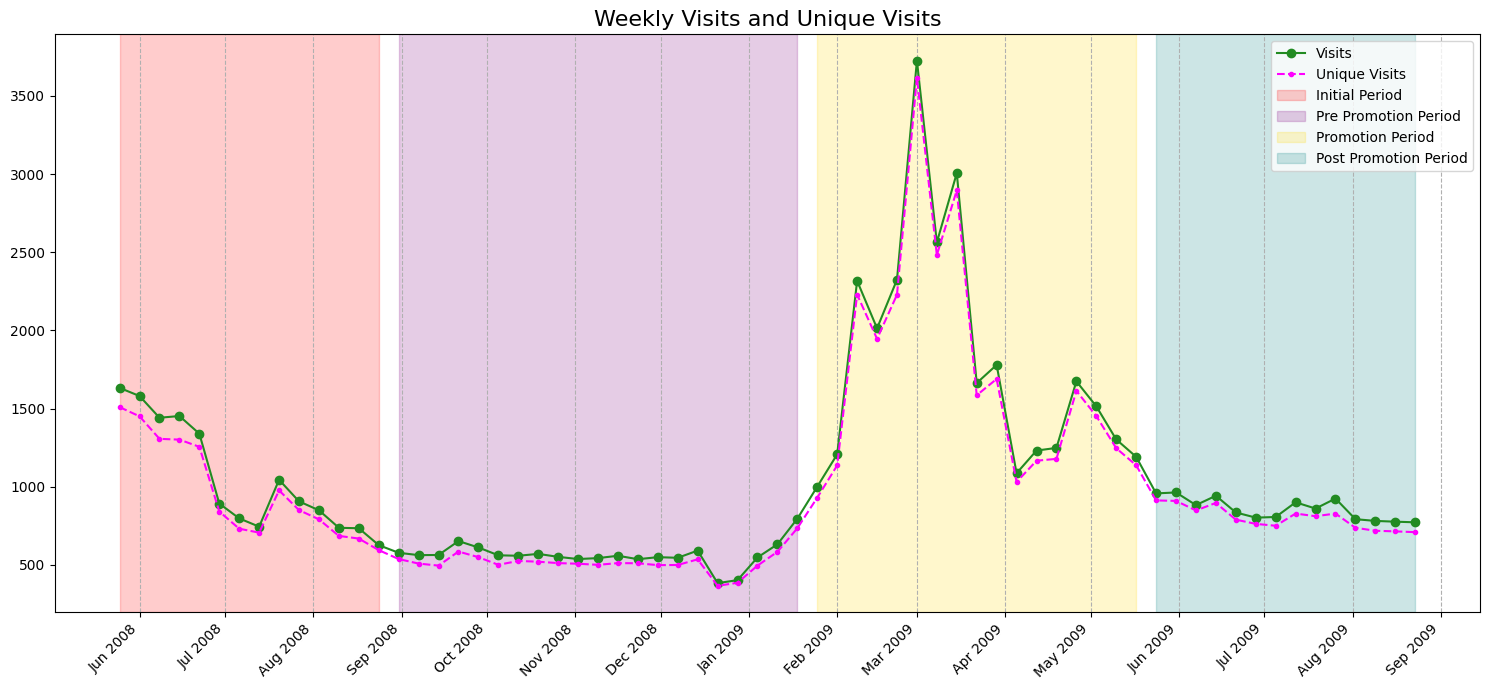

In [5]:


temp_dates = pd.to_datetime(df['Week'], format='%b %d')
month_resets = temp_dates.dt.month.diff() < 0
year_offset = month_resets.cumsum()
correct_year = 2008 + year_offset
df['Week'] = pd.to_datetime(df['Week'] + ', ' + correct_year.astype(str), format='%b %d, %Y')


# plot
plt.figure(figsize=(15, 7))
plt.plot(df['Week'], df['Visits'], marker='o', linestyle='-', color='forestgreen', label='Visits')
plt.plot(df['Week'], df['Unique Visits'], marker='.', linestyle='--', color='magenta', label='Unique Visits')
plt.title('Weekly Visits and Unique Visits', fontsize=16)

ax = plt.gca()

#shading
# Period 1
ax.axvspan(pd.to_datetime('2008-05-25'), pd.to_datetime('2008-08-24'), color='red', alpha=0.2, label='Initial Period')

# Period 2
ax.axvspan(pd.to_datetime('2008-08-31'), pd.to_datetime('2009-01-18'), color='purple', alpha=0.2, label='Pre Promotion Period')

# Period 3
ax.axvspan(pd.to_datetime('2009-01-25'), pd.to_datetime('2009-05-17'), color='gold', alpha=0.2, label='Promotion Period')

# Period 4
ax.axvspan(pd.to_datetime('2009-05-24'), pd.to_datetime('2009-08-23'), color='teal', alpha=0.2, label='Post Promotion Period')


ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45, ha='right')
plt.grid(True, which='major', axis='x', linestyle='--')
plt.legend()
plt.tight_layout()

plt.show()

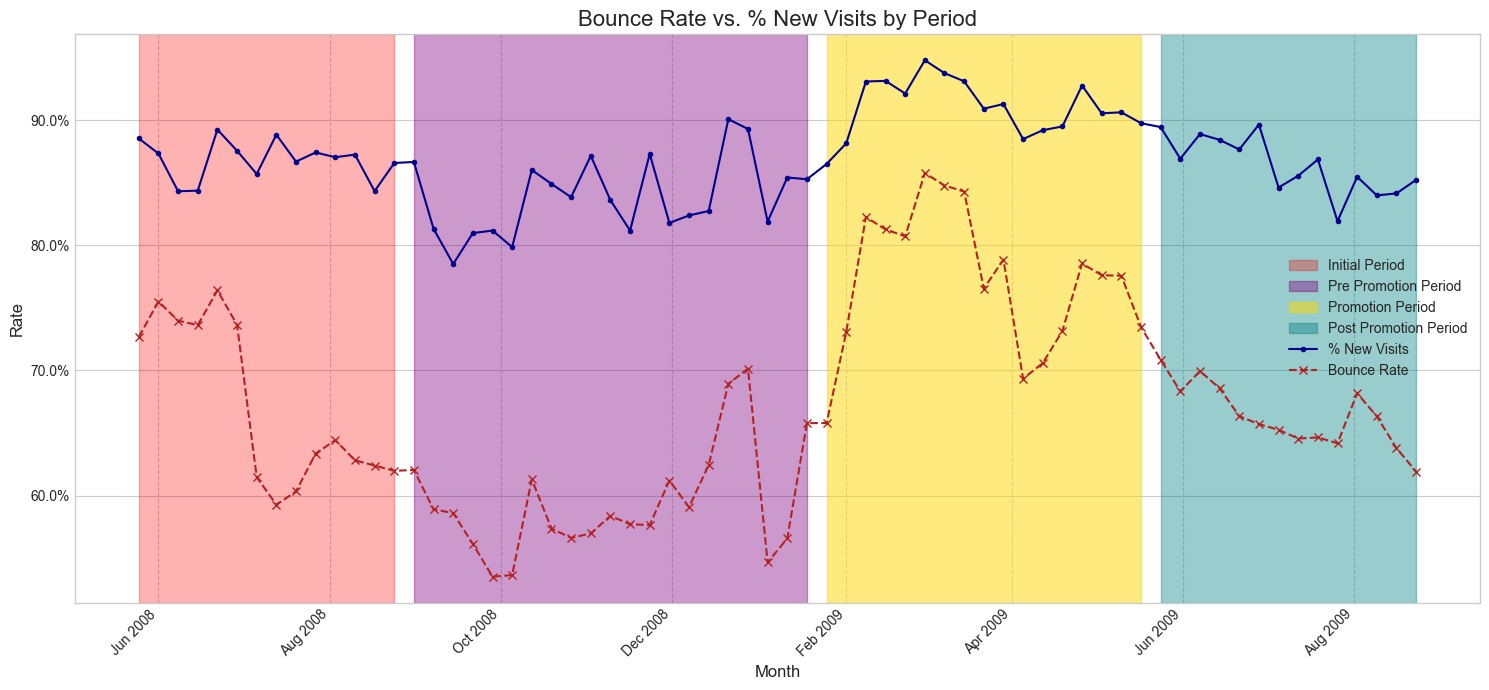

In [6]:

plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(15, 7))

# Shading 
ax.axvspan(pd.to_datetime('2008-05-25'), pd.to_datetime('2008-08-24'), color='red', alpha=0.3, label='Initial Period')
ax.axvspan(pd.to_datetime('2008-08-31'), pd.to_datetime('2009-01-18'), color='purple', alpha=0.4, label='Pre Promotion Period')
ax.axvspan(pd.to_datetime('2009-01-25'), pd.to_datetime('2009-05-17'), color='gold', alpha=0.5, label='Promotion Period')
ax.axvspan(pd.to_datetime('2009-05-24'), pd.to_datetime('2009-08-23'), color='teal', alpha=0.4, label='Post Promotion Period')

#plot data series
ax.plot(df['Week'], df['% New Visits'], marker='.', linestyle='-', color='darkblue', label='% New Visits')

ax.plot(df['Week'], df['Bounce Rate'], marker='x', linestyle='--', color='firebrick', label='Bounce Rate')


ax.set_title('Bounce Rate vs. % New Visits by Period', fontsize=16)
ax.set_ylabel('Rate', fontsize=12)
ax.set_xlabel('Month', fontsize=12)

# foratting
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))


ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.xticks(rotation=45, ha='right')
plt.grid(True, which='major', axis='x', linestyle='--')
plt.legend()
plt.tight_layout()

plt.show()

In [7]:

periods = {
    'Initial Period': ('2008-05-25', '2008-08-24'),
    'Pre-Promotion Period': ('2008-08-31', '2009-01-18'),
    'Promotion Period': ('2009-01-25', '2009-05-17'),
    'Post-Promotion Period': ('2009-05-24', '2009-08-23')
}

def calculate_metrics(df, start_date, end_date):
    
    
    start = pd.to_datetime(start_date)
    end = pd.to_datetime(end_date)
    
    #filtering
    period_df = df[(df['Week'] >= start) & (df['Week'] <= end)]
    
    # Calculate metrics
    total_pageviews = period_df['Pageviews'].sum()
    avg_pages_per_visit = period_df['Pages/Visit'].mean()
    avg_time_on_site = period_df['Avg. Time on Site (secs.)'].mean()
    
    return {
        'Total Pageviews': total_pageviews,
        'Avg. Pages/Visit': avg_pages_per_visit,
        'Avg. Time on Site (s)': avg_time_on_site
    }

# loooooop
results = {}
for name, (start, end) in periods.items():
    results[name] = calculate_metrics(df, start, end)


summary_df = pd.DataFrame(results).T


summary_df['Total Pageviews'] = summary_df['Total Pageviews'].map('{:,.0f}'.format)
summary_df['Avg. Pages/Visit'] = summary_df['Avg. Pages/Visit'].map('{:.2f}'.format)
# --- NEW LINE: Format the new time column ---
summary_df['Avg. Time on Site (s)'] = summary_df['Avg. Time on Site (s)'].map('{:.1f}'.format)



print("Performance Metrics by Period")
print(summary_df)

Performance Metrics by Period
                      Total Pageviews Avg. Pages/Visit Avg. Time on Site (s)
Initial Period                 32,867             2.28                  80.3
Pre-Promotion Period           31,680             2.67                  95.9
Promotion Period               52,731             1.79                  48.8
Post-Promotion Period          26,155             2.18                  70.0


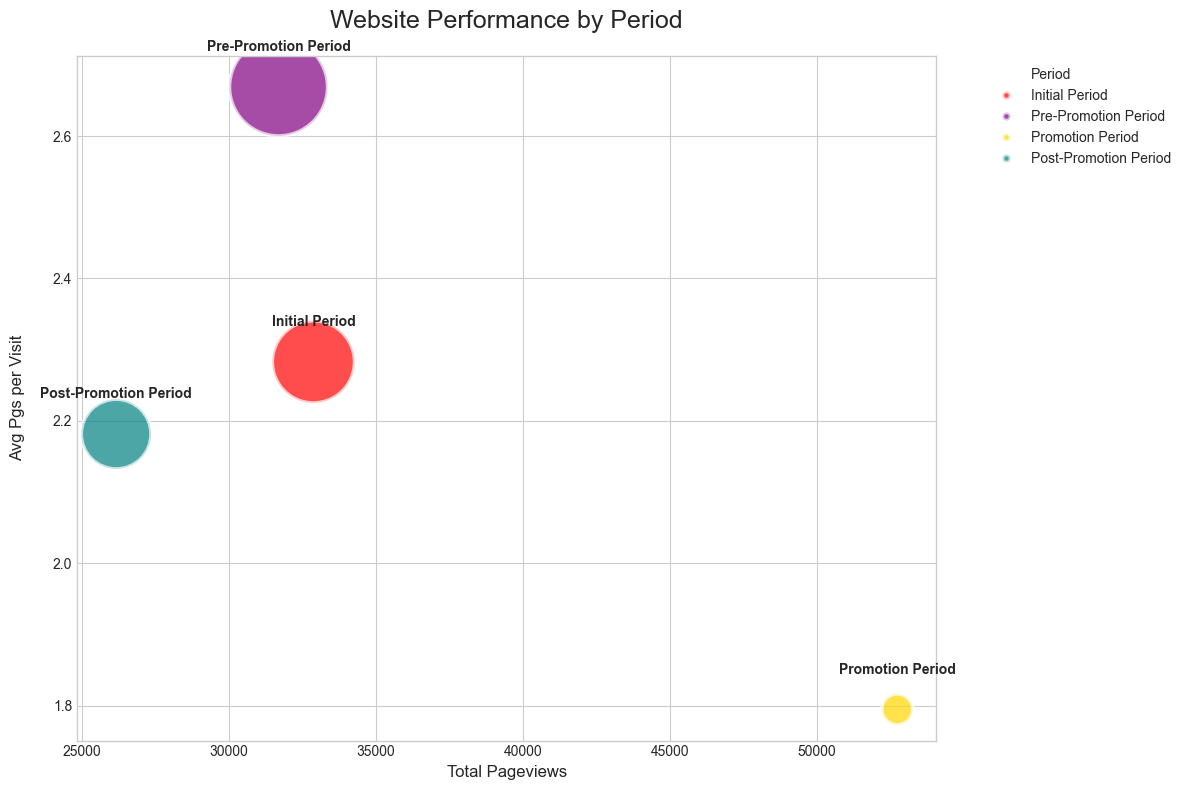

In [8]:
"Position (Left to Right): Bubbles further to the right had higher total traffic (more pageviews)"
"Position (Bottom to Top): Bubbles further to the top had deeper engagement (users visited more pages per visit)."

"Bubble Size: Larger bubbles indicate that users spent more time on the site during that period."



#Calculate metrics
metrics_list = []
for name, (start, end) in periods.items():
    period_df = df[(df['Week'] >= start) & (df['Week'] <= end)]
    metrics = {
        'Period': name,
        'Total Pageviews': period_df['Pageviews'].sum(),
        'Avg. Pages/Visit': period_df['Pages/Visit'].mean(),
        'Avg. Time on Site': period_df['Avg. Time on Site (secs.)'].mean()
    }
    metrics_list.append(metrics)


summary_df = pd.DataFrame(metrics_list)

import seaborn as sns
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(12, 8))

custom_colors = ['red', 'purple', 'gold', 'teal']



bubble_chart = sns.scatterplot(
    data=summary_df,
    x='Total Pageviews',
    y='Avg. Pages/Visit',
    size='Avg. Time on Site',
    hue='Period',  # Color each bubble by its period
    sizes=(500, 5000), 
    alpha=0.7,
    palette=custom_colors, 
    ax=ax
)

for i, row in summary_df.iterrows():
    ax.text(row['Total Pageviews'], row['Avg. Pages/Visit'] + 0.05, row['Period'], 
            ha='center', fontsize=10, fontweight='bold')


ax.set_title('Website Performance by Period', fontsize=18, pad=20)
ax.set_xlabel('Total Pageviews', fontsize=12)
ax.set_ylabel('Avg Pgs per Visit', fontsize=12, labelpad=20)


h, l = bubble_chart.get_legend_handles_labels()

plt.legend(h[0:5], l[0:5], bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

FINANCIAL


In [9]:
file_path = 'qa.xlsx' 
# Use header=4 because row 5 in Excel is the 4th index
financialdf = pd.read_excel(file_path, sheet_name='Financials', header=4) 



financialdf['Week'] = financialdf['Week (2008-2009)'].str.split(' - ').str[0]

temp_dates = pd.to_datetime(financialdf['Week'], format='%b %d')
month_resets = temp_dates.dt.month.diff() < 0
year_offset = month_resets.cumsum()
correct_year = 2008 + year_offset
financialdf['Week'] = pd.to_datetime(financialdf['Week'] + ', ' + correct_year.astype(str), format='%b %d, %Y')

for col in ['Revenue', 'Profit']:
    financialdf[col] = financialdf[col].replace({'\$': '', ',': ''}, regex=True).astype(float)


financialdf = financialdf.drop(columns=['Week (2008-2009)'])


print(financialdf.head())


      Revenue    Profit  Lbs. Sold  Inquiries  Unnamed: 5       Week
0  480728.006  118683.8  16585.183         13         NaN 2008-05-25
1  641155.476  269604.7  18906.380          7         NaN 2008-06-01
2  890076.650  275218.1  28052.924          5         NaN 2008-06-08
3  552673.978  204153.0  19382.312          3         NaN 2008-06-15
4  750776.984  256091.4  24274.249          3         NaN 2008-06-22


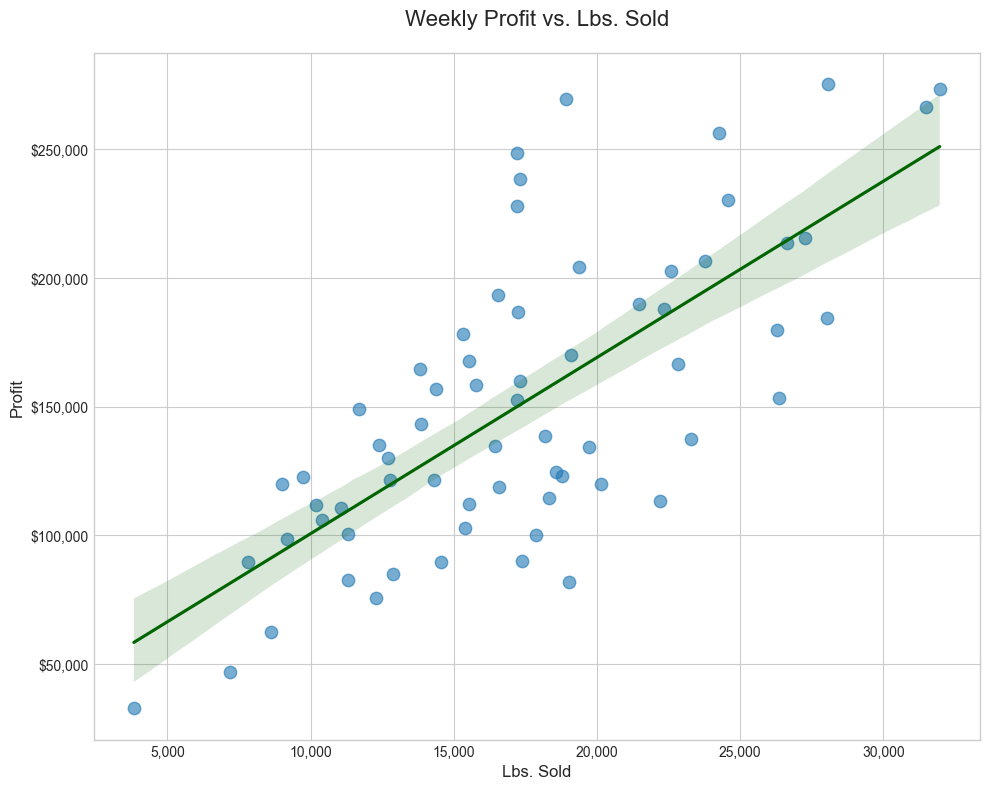

In [10]:

plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(10, 8))

#scatter and regere
sns.regplot(
    data=financialdf,
    x='Lbs. Sold',
    y='Profit',
    ax=ax,
    scatter_kws={'alpha': 0.6, 's': 80},
    line_kws={'color': 'darkgreen'}
)


ax.set_title('Weekly Profit vs. Lbs. Sold', fontsize=16, pad=20)
ax.set_xlabel('Lbs. Sold', fontsize=12)
ax.set_ylabel('Profit', fontsize=12)


y_formatter = FuncFormatter(lambda y, pos: f'${int(y):,}')
x_formatter = FuncFormatter(lambda x, pos: f'{int(x):,}')
ax.yaxis.set_major_formatter(y_formatter)
ax.xaxis.set_major_formatter(x_formatter)

plt.tight_layout()
plt.show()

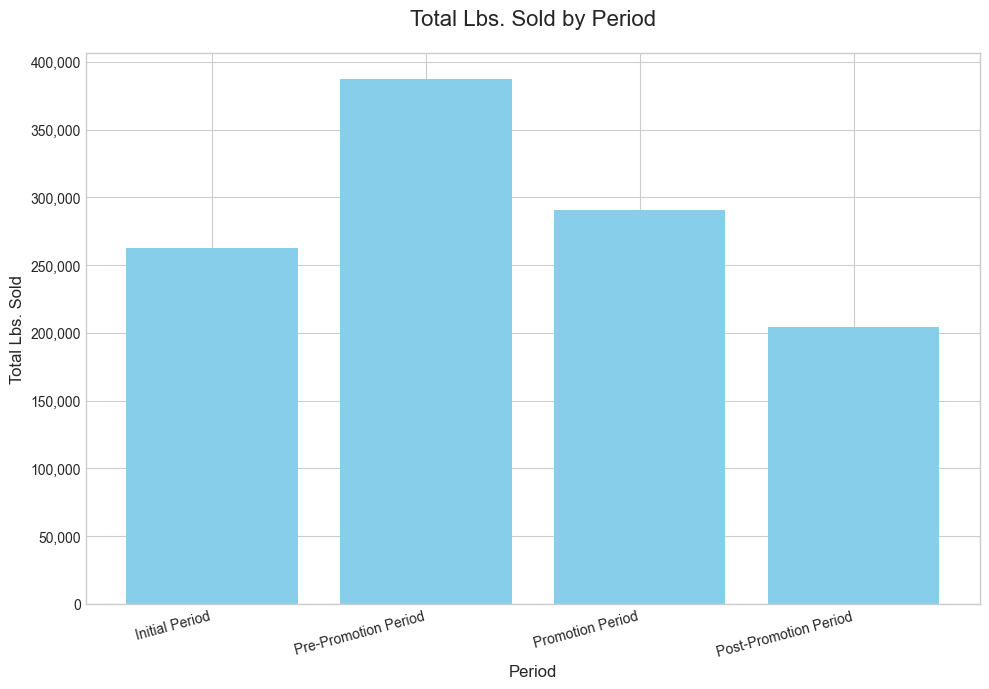

In [11]:


periods = {
    'Initial Period': ('2008-05-25', '2008-08-24'),
    'Pre-Promotion Period': ('2008-08-31', '2009-01-18'),
    'Promotion Period': ('2009-01-25', '2009-05-17'),
    'Post-Promotion Period': ('2009-05-24', '2009-08-23')
}

lbs_sold_by_period = []
for name, (start, end) in periods.items():
    period_df = financialdf[(financialdf['Week'] >= start) & (financialdf['Week'] <= end)]
    total_lbs_sold = period_df['Lbs. Sold'].sum()
    lbs_sold_by_period.append({'Period': name, 'Total Lbs. Sold': total_lbs_sold})

summary_df = pd.DataFrame(lbs_sold_by_period)



plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(10, 7))

ax.bar(summary_df['Period'], summary_df['Total Lbs. Sold'], color='skyblue')


ax.set_title('Total Lbs. Sold by Period', fontsize=16, pad=20)
ax.set_xlabel('Period', fontsize=12)
ax.set_ylabel('Total Lbs. Sold', fontsize=12)

formatter = FuncFormatter(lambda y, pos: f'{int(y):,}')
ax.yaxis.set_major_formatter(formatter)

plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

DEMOGRAPHICS

In [12]:

geo_data = { #just make list instead of import
    'Region': [
        'South America', 'Northern America', 'Central America', 
        'Western Europe', 'Eastern Asia', 'Northern Europe', 
        'Southern Asia', 'South-Eastern Asia', 'Southern Europe', 
        'Eastern Europe'
    ],
    'Visits': [
        22616, 17509, 6776, 5214, 3228, 2721, 
        2589, 1968, 1538, 1427
    ]
}


demodf = pd.DataFrame(geo_data)

print(demodf)

               Region  Visits
0       South America   22616
1    Northern America   17509
2     Central America    6776
3      Western Europe    5214
4        Eastern Asia    3228
5     Northern Europe    2721
6       Southern Asia    2589
7  South-Eastern Asia    1968
8     Southern Europe    1538
9      Eastern Europe    1427


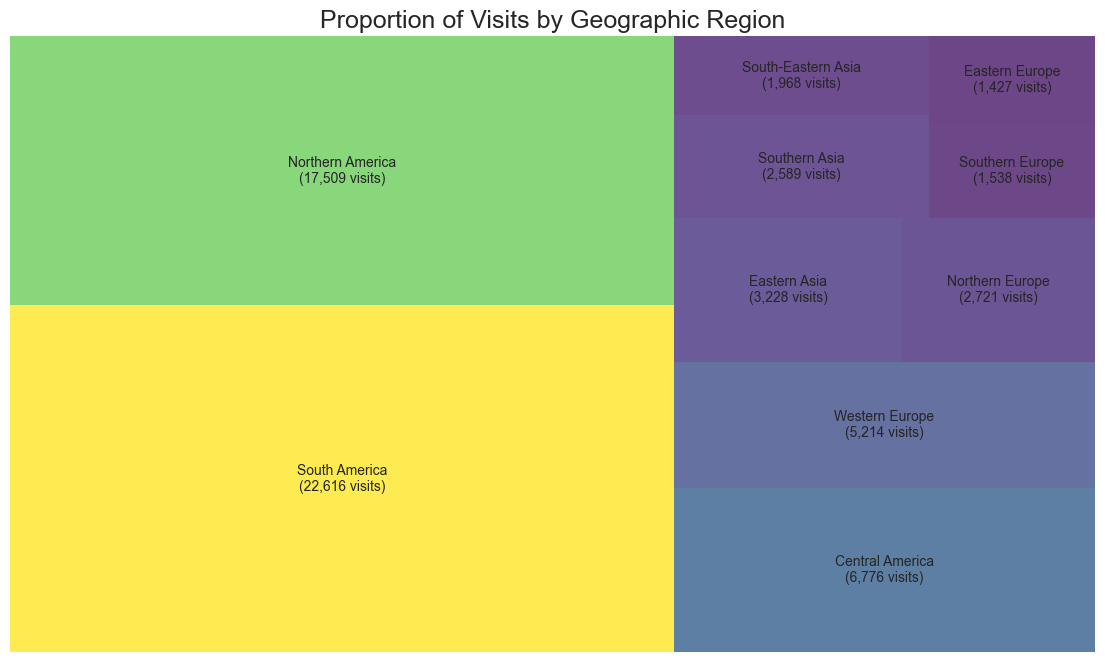

In [13]:
# LAST FIGUREEE


plt.figure(figsize=(14, 8))

labels = [f"{region}\n({visits:,.0f} visits)" for region, visits in zip(demodf['Region'], demodf['Visits'])]

squarify.plot(
    sizes=demodf['Visits'], 
    label=labels, 
    alpha=0.8,
    color=plt.cm.viridis(demodf['Visits'] / demodf['Visits'].max())
)

plt.title('Proportion of Visits by Geographic Region', fontsize=18)
plt.axis('off')
plt.show()

maybe if we target all the highest things in the demograpphics sheet, then u can get more profit